**Importing libraries**

This cell loads the libraries used in the project: `pandas` for tables (DataFrames), `numpy` for numerical operations, `seaborn` and `matplotlib.pyplot` for charts, `nltk` (Natural Language Toolkit) for text processing, and `re` for working with text patterns. The short names (`pd`, `np`, `sns`, `plt`) are standard aliases.

In [237]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import nltk
import re


**Loading the training data**

This reads `SMS_train.csv` into a DataFrame called `df_train`. `encoding='ISO-8859-1'` tells pandas how to read special characters in the messages. Writing `df_train` on the last line displays the table of SMS messages and their labels (Spam or Non-Spam).

In [238]:
train_data = pd.read_csv('SMS_train.csv',encoding = 'ISO-8859-1' )
df_train = pd.DataFrame(train_data)
df_train

,S. No.,Message_body,Label
0,1,Rofl. Its true to its name,Non-Spam
1,2,The guy did some bitching but I acted like i'd...,Non-Spam
2,3,"Pity, * was in mood for that. So...any other s...",Non-Spam
3,4,Will ü b going to esplanade fr home?,Non-Spam
4,5,This is the 2nd time we have tried 2 contact u...,Spam
...,...,...,...
952,953,hows my favourite person today? r u workin har...,Non-Spam
953,954,How much you got for cleaning,Non-Spam
954,955,Sorry da. I gone mad so many pending works wha...,Non-Spam
955,956,Wat time ü finish?,Non-Spam


**Loading the test data**

This reads `SMS_test.csv` into a DataFrame called `df_test`, using the same encoding, and displays it. This file holds a second set of labelled SMS messages.

In [239]:
test_data = pd.read_csv('SMS_test.csv',encoding = 'ISO-8859-1' )
df_test = pd.DataFrame(test_data)
df_test

,S. No.,Message_body,Label
0,1,"UpgrdCentre Orange customer, you may now claim...",Spam
1,2,"Loan for any purpose £500 - £75,000. Homeowner...",Spam
2,3,Congrats! Nokia 3650 video camera phone is you...,Spam
3,4,URGENT! Your Mobile number has been awarded wi...,Spam
4,5,Someone has contacted our dating service and e...,Spam
...,...,...,...
120,121,7 wonders in My WORLD 7th You 6th Ur style 5th...,Non-Spam
121,122,Try to do something dear. You read something f...,Non-Spam
122,123,Sun ah... Thk mayb can if dun have anythin on....,Non-Spam
123,124,"SYMPTOMS when U are in love: ""1.U like listeni...",Non-Spam


**Combining the two datasets**

`pd.concat()` joins the training and test DataFrames one after the other into a single DataFrame called `df`. `ignore_index=True` renumbers the rows from 0 so the index is continuous. The data is split again later in the notebook.

In [240]:
df = pd.concat([df_train,df_test],ignore_index = True)
df

,S. No.,Message_body,Label
0,1,Rofl. Its true to its name,Non-Spam
1,2,The guy did some bitching but I acted like i'd...,Non-Spam
2,3,"Pity, * was in mood for that. So...any other s...",Non-Spam
3,4,Will ü b going to esplanade fr home?,Non-Spam
4,5,This is the 2nd time we have tried 2 contact u...,Spam
...,...,...,...
1077,121,7 wonders in My WORLD 7th You 6th Ur style 5th...,Non-Spam
1078,122,Try to do something dear. You read something f...,Non-Spam
1079,123,Sun ah... Thk mayb can if dun have anythin on....,Non-Spam
1080,124,"SYMPTOMS when U are in love: ""1.U like listeni...",Non-Spam


**Checking the total size**

`size` gives the total number of values in the table, which is rows multiplied by columns.

In [241]:
df.size

3246

**Checking the shape**

`shape` shows the number of rows and columns as `(rows, columns)`. This tells us how many SMS messages are in the combined dataset.

In [242]:
df.shape

(1082, 3)

**Viewing the first rows**

`head()` shows the first 5 rows, which gives a quick look at the columns and the kind of messages in the data.

In [243]:
df.head()

,S. No.,Message_body,Label
0,1,Rofl. Its true to its name,Non-Spam
1,2,The guy did some bitching but I acted like i'd...,Non-Spam
2,3,"Pity, * was in mood for that. So...any other s...",Non-Spam
3,4,Will ü b going to esplanade fr home?,Non-Spam
4,5,This is the 2nd time we have tried 2 contact u...,Spam


**Viewing the last rows**

`tail()` shows the last 5 rows. Looking at both the start and the end of the data helps confirm that it loaded and combined correctly.

In [244]:
df.tail()

,S. No.,Message_body,Label
1077,121,7 wonders in My WORLD 7th You 6th Ur style 5th...,Non-Spam
1078,122,Try to do something dear. You read something f...,Non-Spam
1079,123,Sun ah... Thk mayb can if dun have anythin on....,Non-Spam
1080,124,"SYMPTOMS when U are in love: ""1.U like listeni...",Non-Spam
1081,125,Great. Have a safe trip. Dont panic surrender ...,Non-Spam


**Checking data types**

`dtypes` lists the data type of each column (for example `int64` for numbers and `object` for text).

In [245]:
df.dtypes

,0
S. No.,int64
Message_body,object
Label,object


**Summary of the dataset**

`info()` prints a compact summary with the number of rows, the column names, data types, and the count of non-null (non-empty) values in each column.

In [246]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1082 entries, 0 to 1081
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   S. No.        1082 non-null   int64 
 1   Message_body  1082 non-null   object
 2   Label         1082 non-null   object
dtypes: int64(1), object(2)
memory usage: 25.5+ KB


**Counting missing values**

`isna().sum()` counts the empty values in each column. This shows whether any cleaning for missing data is needed.

In [247]:
df.isna().sum()

,0
S. No.,0
Message_body,0
Label,0


**Checking for duplicate rows**

`duplicated().sum()` counts rows that are exact copies of another row. A result of 0 means there are no duplicate rows.

In [248]:
df.duplicated().sum()

np.int64(0)

**Counting spam and non-spam messages**

`value_counts()` counts how many messages have each label (Spam and Non-Spam) and saves the result in `spam`. This shows how balanced the classes are.

In [249]:
spam = df['Label'].value_counts()
spam

,count
Label,
Non-Spam,884
Spam,198


**Bar chart of spam vs non-spam**

Draws a bar chart of the label counts from the previous cell, with a title and axis labels. It makes it easy to compare the number of spam and non-spam messages.

Text(0, 0.5, 'count')

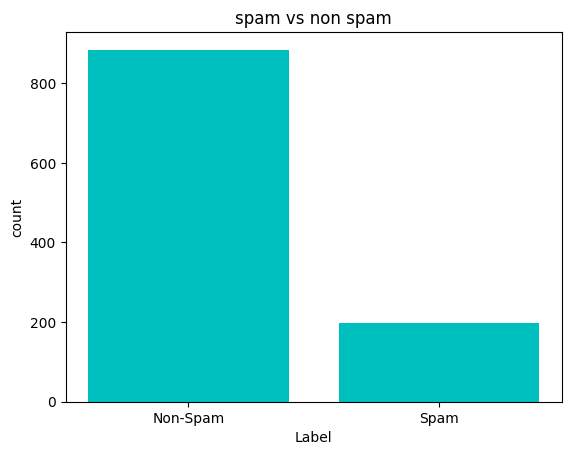

In [250]:
plt.bar(spam.index,spam.values,color = 'c')
plt.title('spam vs non spam')
plt.xlabel('Label')
plt.ylabel('count')

**Listing the column names**

`columns` displays the names of all columns, which we use as a reference in the next step.

In [251]:
df.columns

Index(['S. No.', 'Message_body', 'Label'], dtype='object')

**Dropping the serial number column**

The `S. No.` column is just a row number and is not useful for classification, so it is removed. `axis=1` means columns, and `inplace=True` applies the change directly to `df`. `head()` then shows the result.

In [252]:
df.drop(['S. No.'], axis=1, inplace=True)
df.head()

,Message_body,Label
0,Rofl. Its true to its name,Non-Spam
1,The guy did some bitching but I acted like i'd...,Non-Spam
2,"Pity, * was in mood for that. So...any other s...",Non-Spam
3,Will ü b going to esplanade fr home?,Non-Spam
4,This is the 2nd time we have tried 2 contact u...,Spam


**Converting labels to numbers**

Machine learning models work with numbers, so the text labels are converted using `map()`: Spam becomes `0` and Non-Spam becomes `1`. The line starting with `#` is a comment describing this step.

In [253]:
# Label changing to 0 and 1

df['Label'] = df['Label'].map({'Spam': 0,'Non-Spam': 1})


**Viewing the encoded labels**

`head()` shows the first rows to check that `Label` now contains numbers.

In [254]:
df.head()

,Message_body,Label
0,Rofl. Its true to its name,1
1,The guy did some bitching but I acted like i'd...,1
2,"Pity, * was in mood for that. So...any other s...",1
3,Will ü b going to esplanade fr home?,1
4,This is the 2nd time we have tried 2 contact u...,0


**Selecting the message text**

The `Message_body` column is stored in a variable called `sms`. All the text cleaning in the next steps is applied to this variable.

In [255]:
sms = df.Message_body
sms

,Message_body
0,Rofl. Its true to its name
1,The guy did some bitching but I acted like i'd...
2,"Pity, * was in mood for that. So...any other s..."
3,Will ü b going to esplanade fr home?
4,This is the 2nd time we have tried 2 contact u...
...,...
1077,7 wonders in My WORLD 7th You 6th Ur style 5th...
1078,Try to do something dear. You read something f...
1079,Sun ah... Thk mayb can if dun have anythin on....
1080,"SYMPTOMS when U are in love: ""1.U like listeni..."


**Downloading NLTK resources**

This downloads two NLTK resources: `stopwords` (a list of common words such as "the" and "is") and `punkt_tab` (data used for splitting text into tokens). The output says they are already up to date.

In [256]:
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

**Tokenization**

`TweetTokenizer` splits each message into separate tokens (words and symbols). It works well for short, informal text like SMS messages. The tokens are then joined back into one string with spaces between them.

In [257]:
# Tokenization
from nltk.tokenize import TweetTokenizer
tk = TweetTokenizer()
sms = sms.apply(lambda x:tk.tokenize(x)).apply(lambda x:' '.join(x))
sms

,Message_body
0,Rofl . Its true to its name
1,The guy did some bitching but I acted like i'd...
2,"Pity , * was in mood for that . So ... any oth..."
3,Will ü b going to esplanade fr home ?
4,This is the 2nd time we have tried 2 contact u...
...,...
1077,7 wonders in My WORLD 7th You 6th Ur style 5th...
1078,Try to do something dear . You read something ...
1079,Sun ah ... Thk mayb can if dun have anythin on...
1080,"SYMPTOMS when U are in love : "" 1 . U like lis..."


**Removing special characters**

This replaces every character that is not a letter or a digit (`[^a-zA-Z0-9]`) with a space. It removes punctuation, symbols, and special characters. `regex=True` tells pandas that the pattern is a regular expression.

In [258]:
# remove special characters

sms = sms.str.replace('[^a-zA-Z0-9]',' ',regex=True)
sms

,Message_body
0,Rofl Its true to its name
1,The guy did some bitching but I acted like i d...
2,Pity was in mood for that So any oth...
3,Will b going to esplanade fr home
4,This is the 2nd time we have tried 2 contact u...
...,...
1077,7 wonders in My WORLD 7th You 6th Ur style 5th...
1078,Try to do something dear You read something ...
1079,Sun ah Thk mayb can if dun have anythin on...
1080,SYMPTOMS when U are in love 1 U like lis...


**Removing very short words**

Each message is tokenized again and only words with 3 or more characters are kept. This removes tiny words and leftover fragments that carry little meaning. The words are then joined back into a string.

In [259]:
# minimum characters
# 3 characters
# removing less that 3 characters
sms = sms.apply(lambda x:" ".join([w for w in tk.tokenize(x)if len(w)>=3]))
sms

,Message_body
0,Rofl Its true its name
1,The guy did some bitching but acted like inter...
2,Pity was mood for that any other suggestions
3,Will going esplanade home
4,This the 2nd time have tried contact have won ...
...,...
1077,wonders WORLD 7th You 6th style 5th smile 4th ...
1078,Try something dear You read something for exams
1079,Sun Thk mayb can dun have anythin Thk have boo...
1080,SYMPTOMS when are love like listening songs ge...


**Stemming**

Stemming reduces words to their root form, so related words are treated as the same word (for example, "tried" becomes "tri"). `SnowballStemmer('english')` is used, and each word is also converted to lowercase.

In [260]:
# stemming
from nltk.stem import SnowballStemmer
st = SnowballStemmer('english')
sms= sms.apply(lambda x:[st.stem(i.lower())for i in tk.tokenize(x)]).apply(lambda x:' '.join(x))
sms

,Message_body
0,rofl it true it name
1,the guy did some bitch but act like interest b...
2,piti was mood for that ani other suggest
3,will go esplanad home
4,this the 2nd time have tri contact have won th...
...,...
1077,wonder world 7th you 6th style 5th smile 4th p...
1078,tri someth dear you read someth for exam
1079,sun thk mayb can dun have anythin thk have boo...
1080,symptom when are love like listen song get sto...


**Removing stopwords**

Stopwords are very common words (such as "the", "and", "for") that add little meaning. This cell loads NLTK's English stopword list and removes those words from each message.

In [261]:
# Remove stopwords
from nltk.corpus import stopwords

stop = stopwords.words('english')
sms = sms.apply(lambda x:[i for i in tk.tokenize(x) if i not in stop]).apply(lambda x:' '.join(x))
sms

,Message_body
0,rofl true name
1,guy bitch act like interest buy someth els nex...
2,piti mood ani suggest
3,go esplanad home
4,2nd time tri contact 750 pound prize claim eas...
...,...
1077,wonder world 7th 6th style 5th smile 4th perso...
1078,tri someth dear read someth exam
1079,sun thk mayb dun anythin thk book lesson pilat...
1080,symptom love like listen song get stop see nam...


**Vectorization with TF-IDF**

Models cannot read text, so `TfidfVectorizer` converts each message into a list of numbers. TF-IDF gives each word a weight based on how often it appears in a message and how rare it is across all messages. `fit_transform()` learns the vocabulary and creates the matrix, which is stored in `data`. The output shows a sparse matrix (a compact format that stores only non-zero values).

In [262]:
# vectorization
from sklearn.feature_extraction.text import TfidfVectorizer
vec = TfidfVectorizer()
data = vec.fit_transform(sms)
data

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 8924 stored elements and shape (1082, 2854)>

**Viewing the TF-IDF values**

`print(data)` shows the stored values of the matrix. Each line has the form (message number, word number) followed by that word's TF-IDF weight.

In [263]:
print(data)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 8924 stored elements and shape (1082, 2854)>
  Coords	Values
  (0, 2146)	0.6743246681420616
  (0, 2603)	0.5352804139572925
  (0, 1751)	0.5086856793431558
  (1, 1236)	0.26826339572857744
  (1, 559)	0.3752334020731641
  (1, 353)	0.35437558793533497
  (1, 1533)	0.2174075457753962
  (1, 1391)	0.3187189191538061
  (1, 628)	0.2751324774651613
  (1, 2331)	0.2751324774651613
  (1, 972)	0.30392006451010634
  (1, 1779)	0.26514476216742267
  (1, 2741)	0.22799692523276513
  (1, 1167)	0.32809784984076795
  (1, 1122)	0.1977601804079742
  (2, 1930)	0.5469696796701571
  (2, 1708)	0.5469696796701571
  (2, 418)	0.36716239650585775
  (2, 2429)	0.5165656915002457
  (3, 1192)	0.4955435583228749
  (3, 998)	0.7276196298199478
  (3, 1308)	0.47434824349351806
  (4, 176)	0.26181671272503576
  (4, 2543)	0.18612502049180385
  (4, 2599)	0.20589438654271086
  :	:
  (1079, 1522)	0.24774213284441401
  (1079, 2434)	0.26153957460502464
  (1079, 1724)	0.27068

**Creating the target array**

The `Label` column is converted to a NumPy array and stored in `y`. These are the labels (0 for Spam, 1 for Non-Spam) that the models will learn to predict.

In [264]:
y = df['Label'].values
y

array([1, 1, 1, ..., 1, 1, 1], shape=(1082,))

**Splitting into training and testing data**

`train_test_split` divides the data into a training set (80%) and a testing set (20%) using `test_size=0.2`. The models learn from the training set and are then checked on the testing set. `random_state=42` makes the split the same every time the code runs.

In [265]:
# training and testing
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(data, y, test_size=0.2, random_state=42)


**Model 1: K-Nearest Neighbors (KNN)**

This trains a KNN classifier with `n_neighbors=5`, which predicts a message's label by looking at the 5 most similar training messages. The model is trained with `fit()`, makes predictions on the test data, and `accuracy_score` measures the share of correct predictions. The score is saved in `score_knn` and printed.

In [266]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. K-Nearest Neighbors (KNN)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train, y_train)
score_knn = accuracy_score(y_test, knn.predict(x_test))
print(f"KNN Accuracy: {score_knn}")

KNN Accuracy: 0.8387096774193549


**Model 2: Naive Bayes**

This trains a Multinomial Naive Bayes classifier, a model based on probabilities that is commonly used for text classification such as spam detection. The test accuracy is saved in `score_nb` and printed.

In [267]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# 4. Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(x_train, y_train)
score_nb = accuracy_score(y_test, nb_model.predict(x_test))
print(f"Naive Bayes Accuracy: {score_nb}")

Naive Bayes Accuracy: 0.9493087557603687


**Model 3: Decision Tree**

This trains a Decision Tree classifier, which makes predictions by following a series of yes/no questions. `criterion='entropy'` chooses how the tree decides where to split. The test accuracy is saved in `score_dt` and printed.

In [268]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# 3. Decision Tree
dt_model = DecisionTreeClassifier(random_state=42, criterion='entropy')
dt_model.fit(x_train, y_train)
score_dt = accuracy_score(y_test, dt_model.predict(x_test))
print(f"Decision Tree Accuracy: {score_dt}")

Decision Tree Accuracy: 0.9354838709677419


**Model 4: Random Forest**

This trains a Random Forest classifier, which combines many decision trees and uses their combined vote. Here it uses `n_estimators=5` (5 trees). The test accuracy is saved in `score_rf` and printed.

In [269]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 2. Random Forest
rf_model = RandomForestClassifier(n_estimators=5, random_state=42)
rf_model.fit(x_train, y_train)
score_rf = accuracy_score(y_test, rf_model.predict(x_test))
print(f"Random Forest Accuracy: {score_rf}")

Random Forest Accuracy: 0.9308755760368663


**Comparing model accuracy in a table**

The four accuracy scores are collected into a DataFrame with one row per model. `display()` shows it as a table so the models can be compared easily.

In [270]:
df_accuracy = pd.DataFrame({
    'Model': ['KNN', 'Random Forest', 'Decision Tree', 'Naive Bayes'],
    'Accuracy': [score_knn, score_rf, score_dt, score_nb]
})
display(df_accuracy)

,Model,Accuracy
0,KNN,0.838710
1,Random Forest,0.930876
2,Decision Tree,0.935484
3,Naive Bayes,0.949309


**Bar chart of model comparison**

Draws a bar chart of each model's accuracy. `plt.bar_label()` writes the accuracy value above each bar, and `plt.ylim(0, 1.0)` sets the vertical axis from 0 to 1.

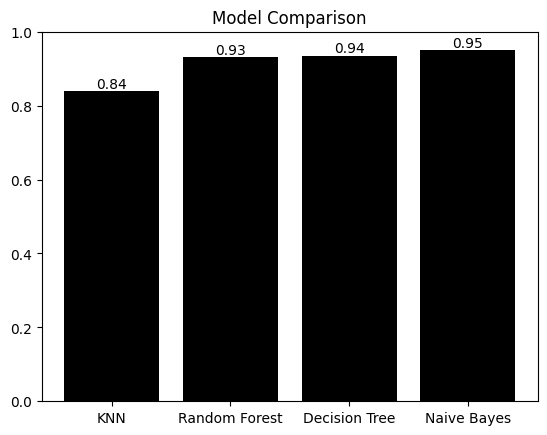

In [271]:
bars = plt.bar(df_accuracy['Model'], df_accuracy['Accuracy'], color='k')
plt.bar_label(bars, fmt='%.2f')
plt.title("Model Comparison")
plt.ylim(0, 1.0)
plt.show()

**Predicting whether a new message is spam**

This tests the trained model on a new SMS message. The text is converted into numbers using the same TF-IDF vectorizer (`vec.transform`), and the Naive Bayes model predicts its label. The result is printed as a word: 0 means Spam and anything else means Non-Spam.

In [281]:
review = ['Hi did u decide wot 2 get 4 his bday if not ill prob jus get him a voucher frm virgin or sumfing ']
data1 = vec.transform(review)
score_nb = nb_model.predict(data1)

if score_nb == 0:
    print('Spam')
else:
    print('Non-Spam')

Non-Spam
